# Lab 00-05 · A Chip-Project Schedule-Risk Simulator

Companion to chapter [00-05](../../chapters/00-05-how-chip-companies-are-organized.md). Handout: [README.md](README.md).

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
rng = np.random.default_rng(2026)
N = 500_000

## 1 — Baseline schedule (Example 00-05.5)

In [2]:
phases = {"verification": (20, 26, 40), "physical design": (10, 12, 20), "fab": (12, 14, 20)}  # <-- edit me

def simulate(phases, respin_prob=0.0, respin=(6, 8, 10), n=N):
    total = sum(rng.triangular(a, m, b, n) for a, m, b in phases.values())
    if respin_prob:
        total = total + np.where(rng.random(n) < respin_prob, rng.triangular(*respin, n), 0.0)
    return total

def report(total, phases, label):
    plan = sum(m for _, m, _ in phases.values())
    print(f"{label}: mean {total.mean():.1f} wk | P(<= plan {plan} wk) = {(total <= plan).mean():.1%} | "
          f"P50 {np.quantile(total, .5):.1f} | P80 {np.quantile(total, .8):.1f} | P95 {np.quantile(total, .95):.1f}")

base = simulate(phases)
report(base, phases, "baseline")
assert abs(base.mean() - 58.0) < 0.05 and abs(np.quantile(base, 0.8) - 62.4) < 0.1

baseline: mean 58.0 wk | P(<= plan 52 wk) = 11.4% | P50 57.7 | P80 62.4 | P95 66.7


## 2 — Add respin risk

**🔮 Predict** the mean and the 80th percentile with a 30% chance of a 6–10-week metal fix.

30% metal-fix risk: mean 60.4 wk | P(<= plan 52 wk) = 8.0% | P50 60.0 | P80 65.7 | P95 71.3


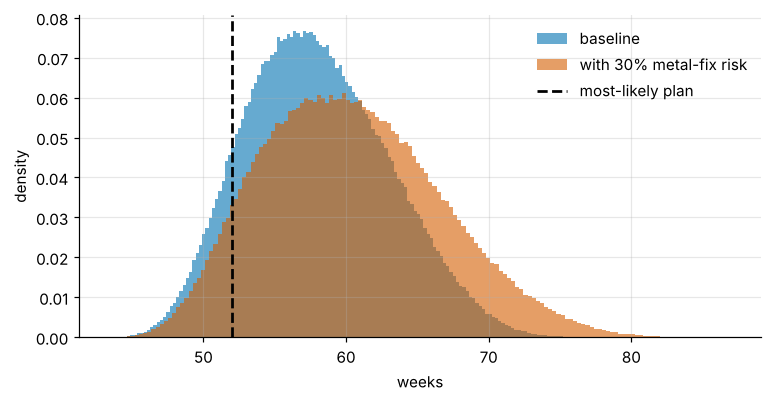

In [3]:
with_fix = simulate(phases, respin_prob=0.30)
report(with_fix, phases, "30% metal-fix risk")
plt.figure(figsize=(8, 3.8))
plt.hist(base, bins=150, density=True, alpha=0.6, label="baseline")
plt.hist(with_fix, bins=150, density=True, alpha=0.6, label="with 30% metal-fix risk")
plt.axvline(sum(m for _, m, _ in phases.values()), color="k", ls="--", label="most-likely plan")
plt.xlabel("weeks"); plt.ylabel("density"); plt.legend(); plt.show()

## 3 — First-silicon success versus integration

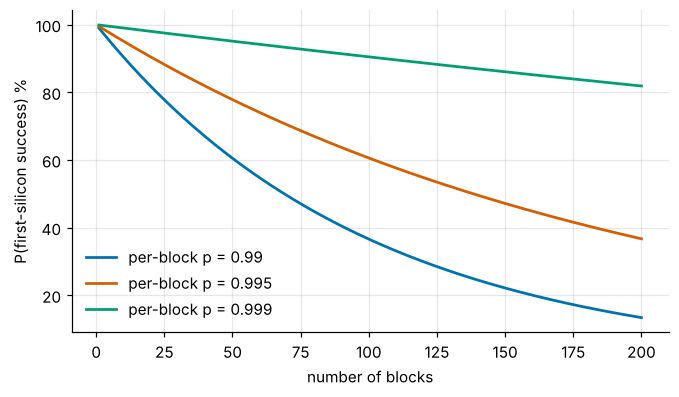

per-block quality for 50% success with 100 blocks: 0.99309


In [4]:
n_blocks = np.arange(1, 201)
plt.figure(figsize=(7, 3.8))
for p in [0.99, 0.995, 0.999]:
    plt.plot(n_blocks, 100 * p ** n_blocks, label=f"per-block p = {p}")
plt.xlabel("number of blocks"); plt.ylabel("P(first-silicon success) %"); plt.legend(); plt.show()
p_needed = 0.5 ** (1 / 100)
print(f"per-block quality for 50% success with 100 blocks: {p_needed:.5f}")